## Часть 1

In [38]:
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader
from torchvision import datasets, transforms, models
import numpy as np

In [39]:
# Set device (GPU if available, otherwise CPU)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Using device: {device}")

# minibatch size. You can try 64 at first, and compare results with 16, 32, 128
batch_size = 32

Using device: cuda


In [40]:
from google.colab import drive
drive.mount('/content/drive/')

Drive already mounted at /content/drive/; to attempt to forcibly remount, call drive.mount("/content/drive/", force_remount=True).


In [41]:
!cp "/content/drive/My Drive/Cats_and_Dogs.zip" "/content/Cats_and_Dogs.zip"

In [42]:
# this code is necessary for unzipping and organizing folders structure in /content/

import zipfile
import os

archive = '/content/Cats_and_Dogs.zip'
destination = '/content/Cats_and_Dogs'

with zipfile.ZipFile(archive, 'r') as zf:
    for member in zf.namelist():

        # Find the position of Cats_and_Dogs in the archive path
        parts = member.split('/')
        if 'Cats_and_Dogs' not in parts:
            continue

        idx = parts.index('Cats_and_Dogs')
        relative_path = os.path.join(*parts[idx+1:])

        if not relative_path:
            continue

        target = os.path.join(destination, relative_path)

        if member.endswith('/'):
            os.makedirs(target, exist_ok=True)
        else:
            os.makedirs(os.path.dirname(target), exist_ok=True)
            with zf.open(member) as src, open(target, 'wb') as dst:
                dst.write(src.read())

print("Extraction completed!")

Extraction completed!


In [43]:
!ls /content/Cats_and_Dogs

test  train  val


In [44]:
# TO FILL

# Initialize the folders with train, test and validation datasets
# Paths are configured here for '/content/Cats_and_Dogs/'

train = '/content/Cats_and_Dogs/train'
val =   '/content/Cats_and_Dogs/val'
test =  '/content/Cats_and_Dogs/test'

# The shape of the RGB image
img_width, img_height, channels = 150, 150, 3 # you can try different scales

# input shape for PyTorch (channels first)
input_shape = (3, img_height, img_width)  # PyTorch uses (N, C, H, W) format for input data - (batch_size, channels, height, width)

# Set device (GPU if available, otherwise CPU)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Using device: {device}")

# minibatch size. You can try 64 at first, and compare results with 16, 32, 128
batch_size = 32


Using device: cuda


In [45]:
!ls /content/Cats_and_Dogs

test  train  val


In [46]:
# Define transforms for data preprocessing
# PyTorch transforms: resize, convert to tensor (scales to [0,1]), and normalize
data_transforms = {
    'train': transforms.Compose([
        transforms.Resize((img_width, img_height)),
        transforms.ToTensor(),  # Converts to tensor and scales to [0, 1]
    ]),
    'val': transforms.Compose([
        transforms.Resize((img_width, img_height)),
        transforms.ToTensor(),
    ]),
    'test': transforms.Compose([
        transforms.Resize((img_width, img_height)),
        transforms.ToTensor(),
    ])
}

# Create datasets using ImageFolder (expects subdirectories for each class)
train_dataset = datasets.ImageFolder(train, transform=data_transforms['train'])
val_dataset = datasets.ImageFolder(val, transform=data_transforms['val'])
test_dataset = datasets.ImageFolder(test, transform=data_transforms['test'])

# Create data loaders
# Note: num_workers=2 for Colab (uses multiprocessing for faster data loading)
train_loader = DataLoader(train_dataset, batch_size=batch_size, shuffle=True, num_workers=2,    pin_memory=True,
    persistent_workers=True)
val_loader = DataLoader(val_dataset, batch_size=batch_size, shuffle=False, num_workers=2,    pin_memory=True,
    persistent_workers=True)
test_loader = DataLoader(test_dataset, batch_size=batch_size, shuffle=False, num_workers=2,    pin_memory=True,
    persistent_workers=True)

In [47]:
class CNNModel(nn.Module):
    def __init__(self):
        super(CNNModel, self).__init__()

        # 1: Convolutional layer with 16 output channels, 3x3 kernel
        self.conv1 = nn.Conv2d(in_channels=3, out_channels=16, kernel_size=3, padding=1)
        self.relu1 = nn.ReLU()

        # 2: MaxPooling layer with 2x2 kernel
        self.pool1 = nn.MaxPool2d(kernel_size=2, stride=2)

        # 3: Convolutional layer with 32 output channels
        self.conv2 = nn.Conv2d(in_channels=16, out_channels=32, kernel_size=3, padding=1)
        self.relu2 = nn.ReLU()

        # 4: Pooling
        self.pool2 = nn.MaxPool2d(kernel_size=2, stride=2)

        # 5: Convolutional (64 channels)
        self.conv3 = nn.Conv2d(in_channels=32, out_channels=64, kernel_size=3, padding=1)
        self.relu3 = nn.ReLU()

        # 6: Pooling
        self.pool3 = nn.MaxPool2d(kernel_size=2, stride=2)

        # 7: Flatten (handled in forward pass)
        # After 3 pooling layers: 150 -> 75 -> 37 -> 18
        # 8: Dense (Fully Connected) with 64 neurons
        self.fc1 = nn.Linear(64 * 18 * 18, 64)
        self.relu4 = nn.ReLU()

        # 9: Dropout(0.5)
        self.dropout = nn.Dropout(0.5)

        # 10: Dense with 1 neuron (no sigmoid if using BCEWithLogitsLoss)
        self.fc2 = nn.Linear(64, 1)

    def forward(self, x):
        x = self.conv1(x)
        x = self.relu1(x)
        x = self.pool1(x)

        x = self.conv2(x)
        x = self.relu2(x)
        x = self.pool2(x)

        x = self.conv3(x)
        x = self.relu3(x)
        x = self.pool3(x)

        x = x.view(x.size(0), -1)

        x = self.fc1(x)
        x = self.relu4(x)
        x = self.dropout(x)
        x = self.fc2(x)

        return x

# Instantiate the model and move to device
model = CNNModel().to(device)
print(model)

CNNModel(
  (conv1): Conv2d(3, 16, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (relu1): ReLU()
  (pool1): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (conv2): Conv2d(16, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (relu2): ReLU()
  (pool2): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (conv3): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (relu3): ReLU()
  (pool3): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (fc1): Linear(in_features=20736, out_features=64, bias=True)
  (relu4): ReLU()
  (dropout): Dropout(p=0.5, inplace=False)
  (fc2): Linear(in_features=64, out_features=1, bias=True)
)


In [48]:
# Define loss function and optimizer
# Binary Cross Entropy with Logits (combines Sigmoid and BCE for better numerical stability)
# Note: If using BCEWithLogitsLoss, remove sigmoid from model's last layer
criterion = nn.BCEWithLogitsLoss()
# Alternatively: use nn.BCELoss() if you keep sigmoid in the model

optimizer = optim.Adam(model.parameters(), lr=0.001)

In [49]:

# Training loop for PyTorch

# you can try different number of epochs: 10, 15, 20; check the learning curves, loss and accuracy;
num_epochs =  10

# Lists to store training history
train_losses = []
train_accuracies = []
val_losses = []
val_accuracies = []

# Main training loop
for epoch in range(num_epochs):
    # Training phase
    model.train()

    running_loss = 0.0
    correct = 0
    total = 0

    for images, labels in train_loader:
        images, labels = images.to(device), labels.to(device)
        labels = labels.float().unsqueeze(1)  # Reshape for binary classification

        # Zero the parameter gradients
        optimizer.zero_grad()

        # Forward pass
        outputs = model(images)
        loss = criterion(outputs, labels)

        # Backward pass and optimize
        loss.backward()
        optimizer.step()

        # Statistics
        running_loss += loss.item()
        predicted = (torch.sigmoid(outputs) > 0.5).float()
        total += labels.size(0)
        correct += (predicted == labels).sum().item()

    train_loss = running_loss / len(train_loader)
    train_acc = 100 * correct / total
    train_losses.append(train_loss)
    train_accuracies.append(train_acc)

    # Validation phase
    model.eval()
    val_running_loss = 0.0
    val_correct = 0
    val_total = 0

    with torch.no_grad():
        for images, labels in val_loader:
            images, labels = images.to(device), labels.to(device)
            labels = labels.float().unsqueeze(1)

            outputs = model(images)
            loss = criterion(outputs, labels)

            val_running_loss += loss.item()
            predicted = (torch.sigmoid(outputs) > 0.5).float()
            val_total += labels.size(0)
            val_correct += (predicted == labels).sum().item()

    val_loss = val_running_loss / len(val_loader)
    val_acc = 100 * val_correct / val_total
    val_losses.append(val_loss)
    val_accuracies.append(val_acc)

    print(f'Epoch [{epoch+1}/{num_epochs}], '
          f'Train Loss: {train_loss:.4f}, Train Acc: {train_acc:.2f}%, '
          f'Val Loss: {val_loss:.4f}, Val Acc: {val_acc:.2f}%')

Epoch [1/10], Train Loss: 0.6457, Train Acc: 61.98%, Val Loss: 0.5549, Val Acc: 71.53%
Epoch [2/10], Train Loss: 0.5397, Train Acc: 72.55%, Val Loss: 0.4898, Val Acc: 77.39%
Epoch [3/10], Train Loss: 0.4741, Train Acc: 77.40%, Val Loss: 0.4462, Val Acc: 78.96%
Epoch [4/10], Train Loss: 0.4158, Train Acc: 81.33%, Val Loss: 0.4268, Val Acc: 80.32%
Epoch [5/10], Train Loss: 0.3759, Train Acc: 83.09%, Val Loss: 0.4106, Val Acc: 81.00%
Epoch [6/10], Train Loss: 0.3342, Train Acc: 85.31%, Val Loss: 0.3936, Val Acc: 82.41%
Epoch [7/10], Train Loss: 0.2953, Train Acc: 87.34%, Val Loss: 0.3879, Val Acc: 81.77%
Epoch [8/10], Train Loss: 0.2632, Train Acc: 88.59%, Val Loss: 0.4451, Val Acc: 81.45%
Epoch [9/10], Train Loss: 0.2279, Train Acc: 90.25%, Val Loss: 0.4191, Val Acc: 82.13%
Epoch [10/10], Train Loss: 0.1988, Train Acc: 91.53%, Val Loss: 0.5044, Val Acc: 81.12%


In [50]:
# Evaluate on test data
model.eval()
test_correct = 0
test_total = 0

with torch.no_grad():
    for images, labels in test_loader:
        images, labels = images.to(device), labels.to(device)
        labels = labels.float().unsqueeze(1)

        outputs = model(images)
        predicted = (torch.sigmoid(outputs) > 0.5).float()
        test_total += labels.size(0)
        test_correct += (predicted == labels).sum().item()

test_accuracy = 100 * test_correct / test_total
print(f"Accuracy on test data: {test_accuracy:.2f}%")

Accuracy on test data: 82.24%


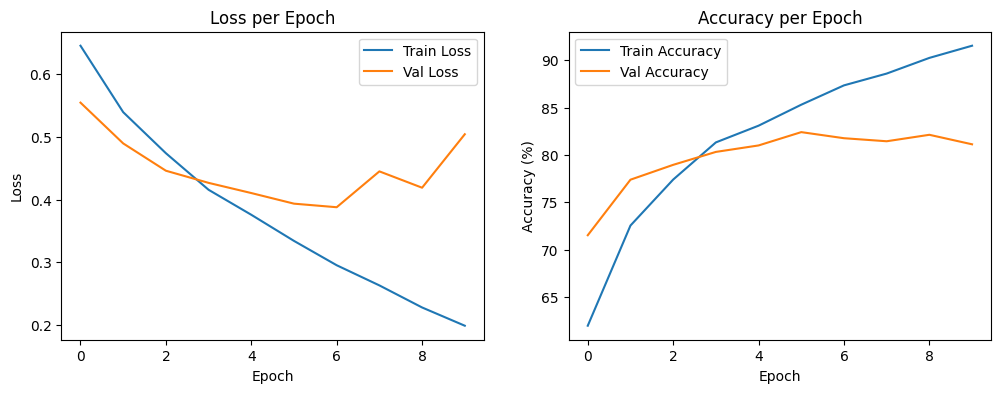

In [51]:
# TO FILL

import matplotlib.pyplot as plt

# Plot Loss
plt.figure(figsize=(12, 4))
plt.subplot(1, 2, 1)
plt.plot(train_losses, label='Train Loss')
plt.plot(val_losses, label='Val Loss')
plt.title('Loss per Epoch')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()

# Plot Accuracy
plt.subplot(1, 2, 2)
plt.plot(train_accuracies, label='Train Accuracy')
plt.plot(val_accuracies, label='Val Accuracy')
plt.title('Accuracy per Epoch')
plt.xlabel('Epoch')
plt.ylabel('Accuracy (%)')
plt.legend()
plt.show()

## Часть 2

### VGG16

In [52]:
# First, download the weights of the VGG16 network trained on the ImageNet dataset:
# PyTorch will automatically download the weights when you first run this

vgg16_net = models.vgg16(pretrained=True)  # Load pre-trained VGG16
# Remove the classifier (fully connected layers) - we take only the "convolution" part
vgg16_net = vgg16_net.features  # Extract only convolutional features

# Freeze the weights - we do NOT want to retrain the VGG16 layers
# Weights VGG16 in the process of learning will remain unchanged!
for param in vgg16_net.parameters():
    param.requires_grad = False

print(vgg16_net)  # pay attention to the architecture

Sequential(
  (0): Conv2d(3, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (1): ReLU(inplace=True)
  (2): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (3): ReLU(inplace=True)
  (4): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (5): Conv2d(64, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (6): ReLU(inplace=True)
  (7): Conv2d(128, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (8): ReLU(inplace=True)
  (9): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (10): Conv2d(128, 256, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (11): ReLU(inplace=True)
  (12): Conv2d(256, 256, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (13): ReLU(inplace=True)
  (14): Conv2d(256, 256, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (15): ReLU(inplace=True)
  (16): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (17): Conv2d(256, 512, kernel_si

In [53]:
# Build transfer learning model by adding fully connected layers to VGG16

class VGG16TransferModel(nn.Module):
    def __init__(self, vgg16_features):
        super(VGG16TransferModel, self).__init__()
        self.features = vgg16_features  # Pre-trained VGG16 features

        # Adaptive pooling to handle feature input sizes
        # That operation shrinks the feature map size to 7x7
        self.avgpool = nn.AdaptiveAvgPool2d((7, 7))

        # Flattening (done in forward)
        # Dense fully connected layer with 256 neurons
        self.fc1 = nn.Linear(512 * 7 * 7, 256)  # VGG16 outputs 512 channels
        self.relu = nn.ReLU()

        # Dropout
        self.dropout = nn.Dropout(0.5)

        # Dense layer with 1 neuron (no sigmoid if using BCEWithLogitsLoss)
        self.fc2 = nn.Linear(256, 1)

    def forward(self, x):
        x = self.features(x)
        x = self.avgpool(x)
        x = torch.flatten(x, 1)  # Flatten

        x = self.fc1(x)
        x = self.relu(x)
        x = self.dropout(x)
        x = self.fc2(x)

        return x

model = VGG16TransferModel(vgg16_net).to(device)
print(model)

VGG16TransferModel(
  (features): Sequential(
    (0): Conv2d(3, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): ReLU(inplace=True)
    (2): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (3): ReLU(inplace=True)
    (4): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (5): Conv2d(64, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (6): ReLU(inplace=True)
    (7): Conv2d(128, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (8): ReLU(inplace=True)
    (9): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (10): Conv2d(128, 256, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (11): ReLU(inplace=True)
    (12): Conv2d(256, 256, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (13): ReLU(inplace=True)
    (14): Conv2d(256, 256, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (15): ReLU(inplace=True)
    (16): MaxPool2d(kernel_size=2, stride=2, paddin

In [54]:
# Define loss and optimizer for transfer learning model
criterion = nn.BCEWithLogitsLoss()
optimizer = optim.Adam(model.parameters(), lr=1e-5)  # Lower learning rate 1e-5 for fine-tuning

In [55]:
# TO FILL

# Training loop for transfer learning model

num_epochs_transfer = 5

# Lists to store training history
train_losses_transfer = []
train_accuracies_transfer = []
val_losses_transfer = []
val_accuracies_transfer = []

for epoch in range(num_epochs_transfer):
    # Training
    model.train()
    running_loss = 0.0
    correct = 0
    total = 0

    for images, labels in train_loader:
        images, labels = images.to(device), labels.to(device)
        labels = labels.float().unsqueeze(1)

        optimizer.zero_grad()
        outputs = model(images)
        loss = criterion(outputs, labels)
        loss.backward()
        optimizer.step()

        running_loss += loss.item()
        predicted = (torch.sigmoid(outputs) > 0.5).float()
        total += labels.size(0)
        correct += (predicted == labels).sum().item()

    train_loss = running_loss / len(train_loader)
    train_acc = 100 * correct / total
    train_losses_transfer.append(train_loss)
    train_accuracies_transfer.append(train_acc)

    # Validation
    model.eval()
    val_running_loss = 0.0
    val_correct = 0
    val_total = 0

    with torch.no_grad():
        for images, labels in val_loader:
            images, labels = images.to(device), labels.to(device)
            labels = labels.float().unsqueeze(1)

            outputs = model(images)
            loss = criterion(outputs, labels)

            val_running_loss += loss.item()
            predicted = (torch.sigmoid(outputs) > 0.5).float()
            val_total += labels.size(0)
            val_correct += (predicted == labels).sum().item()

    val_loss = val_running_loss / len(val_loader)
    val_acc = 100 * val_correct / val_total
    val_losses_transfer.append(val_loss)
    val_accuracies_transfer.append(val_acc)

    print(f'Epoch [{epoch+1}/{num_epochs_transfer}], '
          f'Train Loss: {train_loss:.4f}, Train Acc: {train_acc:.2f}%, '
          f'Val Loss: {val_loss:.4f}, Val Acc: {val_acc:.2f}%')

Epoch [1/5], Train Loss: 0.1699, Train Acc: 93.61%, Val Loss: 0.1196, Val Acc: 95.26%
Epoch [2/5], Train Loss: 0.1121, Train Acc: 95.65%, Val Loss: 0.1083, Val Acc: 95.86%
Epoch [3/5], Train Loss: 0.0973, Train Acc: 96.19%, Val Loss: 0.1086, Val Acc: 95.74%
Epoch [4/5], Train Loss: 0.0879, Train Acc: 96.61%, Val Loss: 0.1026, Val Acc: 96.02%
Epoch [5/5], Train Loss: 0.0799, Train Acc: 96.96%, Val Loss: 0.1071, Val Acc: 95.90%


In [56]:
# Evaluate transfer learning model on test data
model.eval()
test_correct = 0
test_total = 0

with torch.no_grad():
    for images, labels in test_loader:
        images, labels = images.to(device), labels.to(device)
        labels = labels.float().unsqueeze(1)

        outputs = model(images)
        predicted = (torch.sigmoid(outputs) > 0.5).float()
        test_total += labels.size(0)
        test_correct += (predicted == labels).sum().item()

test_accuracy = 100 * test_correct / test_total
print(f"Accuracy on test data: {test_accuracy:.2f}%")

Accuracy on test data: 94.88%


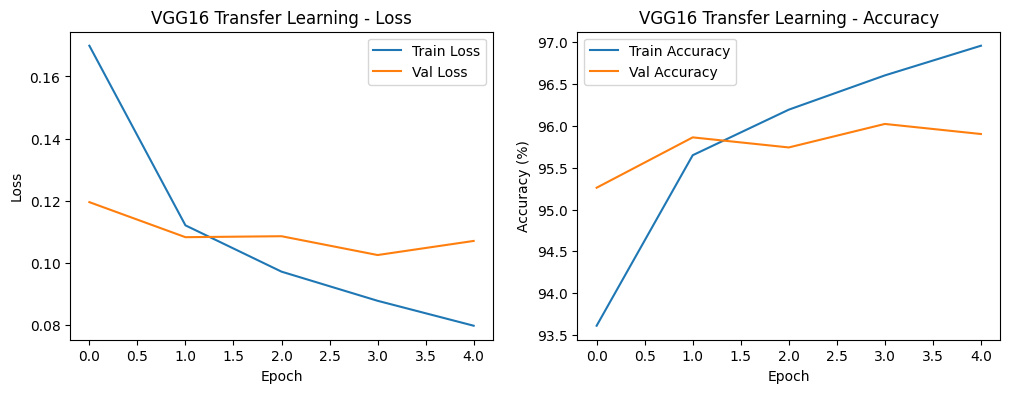

In [57]:
plt.figure(figsize=(12, 4))
plt.subplot(1, 2, 1)
plt.plot(train_losses_transfer, label='Train Loss')
plt.plot(val_losses_transfer, label='Val Loss')
plt.title('VGG16 Transfer Learning - Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(train_accuracies_transfer, label='Train Accuracy')
plt.plot(val_accuracies_transfer, label='Val Accuracy')
plt.title('VGG16 Transfer Learning - Accuracy')
plt.xlabel('Epoch')
plt.ylabel('Accuracy (%)')
plt.legend()
plt.show()

### Another Transfer Learning model: ResNet18

In [58]:
# Используем ResNet18
resnet18_net = models.resnet18(pretrained=True)
# Замораживаем сверточные слои (все, кроме последнего fc)
for param in resnet18_net.parameters():
    param.requires_grad = False

# Меняем последний слой под бинарную классификацию
resnet18_net.fc = nn.Linear(resnet18_net.fc.in_features, 1)

model_resnet = resnet18_net.to(device)

# Дальше цикл обучения точно такой же, как для VGG16,
# только не забудьте поменять названия переменных в списках истории (или создайте новые).

In [59]:
# from PIL import Image

# def predict_image(image_path, model, device):
#     # Открываем картинку и обязательно переводим в RGB (на случай PNG с альфа-каналом)
#     image = Image.open(image_path).convert('RGB')

#     # Применяем те же трансформации, что и при обучении
#     transform = transforms.Compose([
#         transforms.Resize((150, 150)),
#         transforms.ToTensor(),
#     ])

#     image_tensor = transform(image).unsqueeze(0).to(device) # Добавляем размерность батча (1, 3, 150, 150)

#     model.eval()
#     with torch.no_grad():
#         output = model(image_tensor)
#         prob = torch.sigmoid(output).item()

#     if prob > 0.5:
#         return "Dog", prob
#     else:
#         return "Cat", 1 - prob # Возвращаем вероятность для выбранного класса

In [68]:
from PIL import Image

def predict_image(image_path, model, device):
    """
    Predicts whether the image is a cat or a dog.
    """
    image = Image.open(image_path).convert('RGB')

    transform = transforms.Compose([
        transforms.Resize((150, 150)),
        transforms.ToTensor(),
        transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
    ])

    image_tensor = transform(image).unsqueeze(0).to(device)

    model.eval()
    with torch.no_grad():
        output = model(image_tensor)
        prob = torch.sigmoid(output).item()

    if prob > 0.5:
        return "Dog", prob
    else:
        return "Cat", 1 - prob

Predicted: Cat with confidence 98.24%


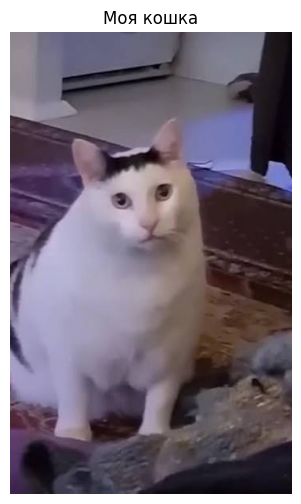

In [71]:

my_image_path = '/content/test_cat1.jpg'

predicted_class, confidence = predict_image(my_image_path, model, device)

print(f"Predicted: {predicted_class} with confidence {confidence*100:.2f}%")

img = Image.open(my_image_path)

plt.figure(figsize=(6, 6))
plt.imshow(img)
plt.axis('off')
plt.title("Моя кошка")
plt.show()

Predicted: Dog with confidence 100.00%


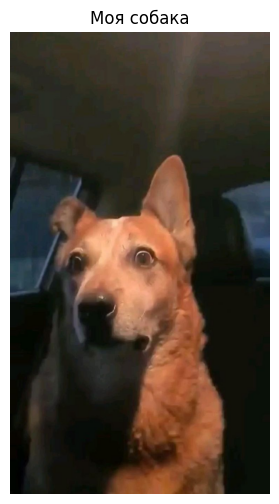

In [72]:
image_path = '/content/test_dog.jpg'

predicted_class, confidence = predict_image(image_path, model, device)

print(f"Predicted: {predicted_class} with confidence {confidence*100:.2f}%")

img = Image.open(image_path)

plt.figure(figsize=(6, 6))
plt.imshow(img)
plt.axis('off')
plt.title("Моя собака")
plt.show()